In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q rdkit

import pandas as pd, numpy as np
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
RDLogger.DisableLog("rdApp.*")

base = "/content/drive/MyDrive/NIR_Thesis"
preds = pd.read_csv(f"{base}/results/multiseed_predictions.csv")
preds["err_xgb"] = preds.xgb_nm - preds.true_nm       # positive = predicted too red
preds["err_dmpnn"] = preds.dmpnn_nm - preds.true_nm
print(len(preds), "predictions,", preds.chrom.nunique(), "unique molecules")

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 40.7 MB/s eta 0:00:00
8894 predictions, 2712 unique molecules


 true_nm  dmpnn_nm  xgb_nm                                                                                                                         solv
   731.0     472.0   471.0                                                                                                                      C1CCOC1
   738.0     486.0   579.0                                                                                                                      CS(C)=O
   740.0     492.0   602.0                                                                                                                      CS(C)=O
   738.0     504.0   596.0                                                                                                                      CS(C)=O
   738.0     505.0   613.0                                                                                                                      CS(C)=O
   756.0     578.0   609.0                                                              

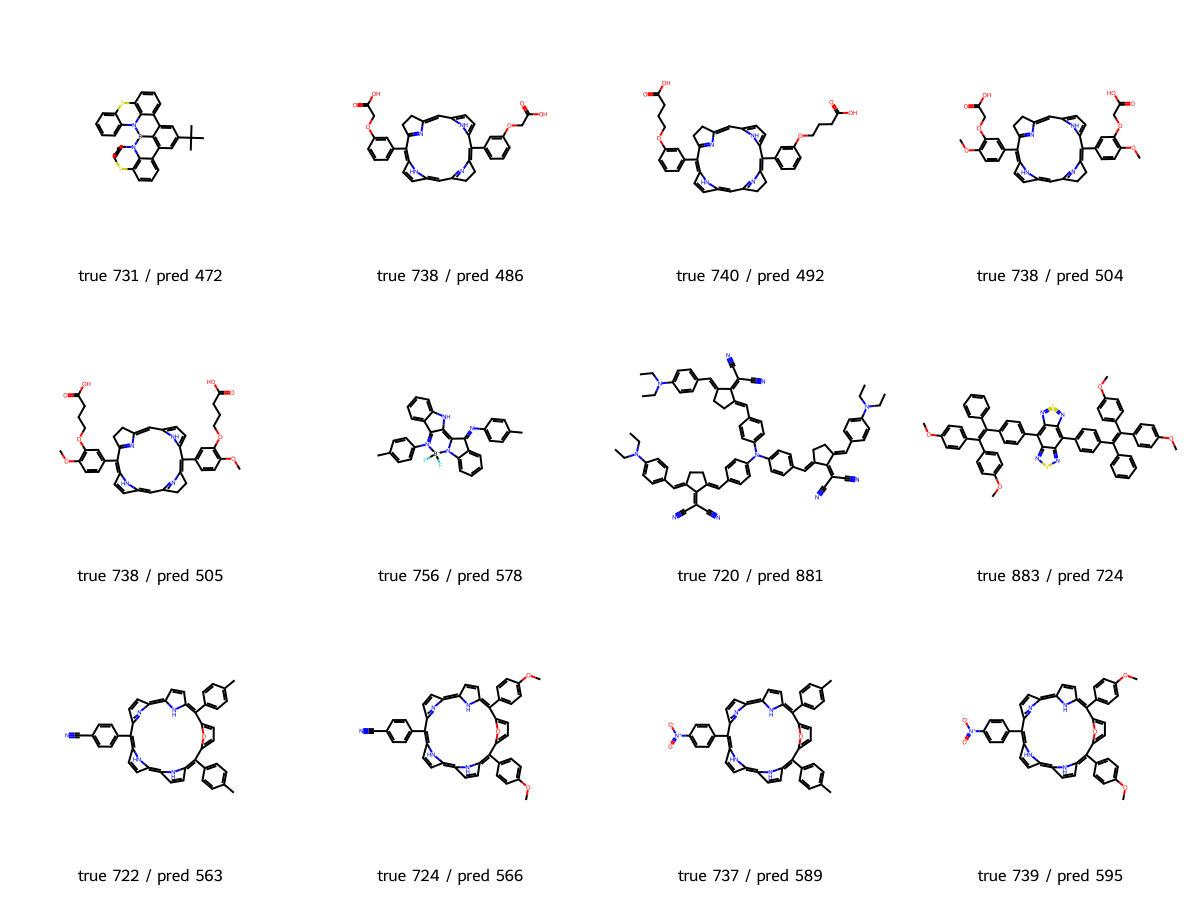

In [16]:
nir = preds[preds.true_nm >= 700].copy()
nir["abs_err"] = nir.err_dmpnn.abs()
worst = nir.sort_values("abs_err", ascending=False).drop_duplicates("chrom").head(12)
print(worst[["true_nm", "dmpnn_nm", "xgb_nm", "solv"]].round(0).to_string(index=False))

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in worst.chrom], molsPerRow=4, subImgSize=(300, 300),
                     legends=[f"true {t:.0f} / pred {p:.0f}" for t, p in zip(worst.true_nm, worst.dmpnn_nm)])

In [17]:
P = Chem.MolFromSmarts
PATTERNS = {
    "subphthalocyanine": P("[#5](~[#7])(~[#7])(~[#7])-[Cl,F,O]"),
    "aza-BODIPY": P("[#5]1~[#7]2~[#6]~[#6]~[#6]~[#6]~2~[#7]~[#6]2~[#6]~[#6]~[#6]~[#7]~12"),
    "BODIPY": P("[#5]1~[#7]2~[#6]~[#6]~[#6]~[#6]~2~[#6]~[#6]2~[#6]~[#6]~[#6]~[#7]~12"),
    "other B-N dye": P("[#5](~[#7])~[#7]"),
    "squaraine": P("[#6]1(~[#8])~[#6]~[#6](~[#8])~[#6]~1"),
    "benzothiadiazole D-A": P("[#7]1~[#16]~[#7]~[#6]~[#6]~1"),
    "xanthene": P("[#6]1~[#6]~[#6]2~[#8]~[#6]3~[#6]~[#6]~[#6]~[#6]~[#6]~3~[#6]~[#6]~2~[#6]~[#6]~1"),
    "DPP": P("[#8]=[#6]1~[#7]~[#6]~[#6]2~[#6](=[#8])~[#7]~[#6]~[#6]~12"),
    "perylene/PDI": P("c1cc2cccc3c4cccc5cccc(c(c1)c23)c54"),
    "coumarin": P("O=c1ccc2ccccc2o1"),
}
# cyanines: N+=C-(C=C)n-N with 1 to 5 C=C units (mono- up to nonamethine)
CYANINE = [P("[#7+]=[#6]" + "-[#6]=[#6]" * k + "-[#7]") for k in range(1, 6)]

def dye_family(smi):
    m = Chem.MolFromSmiles(smi)
    for ring in m.GetRingInfo().AtomRings():          # porphyrins: big ring with 4 N
        if len(ring) >= 15 and sum(m.GetAtomWithIdx(i).GetSymbol() == "N" for i in ring) >= 4:
            return "porphyrin"
    for name in ["subphthalocyanine", "aza-BODIPY", "BODIPY", "other B-N dye", "squaraine"]:
        if m.HasSubstructMatch(PATTERNS[name]):
            return name
    if any(m.HasSubstructMatch(p) for p in CYANINE):
        return "cyanine"
    for name in ["benzothiadiazole D-A", "xanthene", "DPP", "perylene/PDI", "coumarin"]:
        if m.HasSubstructMatch(PATTERNS[name]):
            return name
    return "other"

family = {s: dye_family(s) for s in preds.chrom.unique()}
preds["family"] = preds.chrom.map(family)
preds.drop_duplicates("chrom").family.value_counts()

,count
family,
other,1991
BODIPY,181
coumarin,123
perylene/PDI,106
xanthene,74
aza-BODIPY,51
other B-N dye,47
porphyrin,42
benzothiadiazole D-A,40


In [18]:
heavy = {s: Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in preds.solv.unique()}

def environment(chrom, solv):
    if chrom == solv:
        return "neat film"
    if heavy[solv] > 20:
        return "doped film (host)"
    return "solution"

preds["environment"] = [environment(c, s) for c, s in zip(preds.chrom, preds.solv)]

rows = []
for env, g in preds.groupby("environment"):
    rows.append({"environment": env, "predictions": len(g), "molecules": g.chrom.nunique(),
                 "XGB MAE": round(g.err_xgb.abs().mean(), 1), "D-MPNN MAE": round(g.err_dmpnn.abs().mean(), 1)})
pd.DataFrame(rows)

,environment,predictions,molecules,XGB MAE,D-MPNN MAE
0,doped film (host),120,95,21.0,22.2
1,neat film,477,398,31.1,30.0
2,solution,8297,2645,35.2,33.6


In [12]:
def family_table(df):
    rows = []
    for f, g in df.groupby("family"):
                rows.append({"family": f, "n": len(g), "molecules": g.chrom.nunique(),
                     "median true nm": g.true_nm.median(),
                     "XGB MAE": g.err_xgb.abs().mean(), "D-MPNN MAE": g.err_dmpnn.abs().mean(),
                     "XGB bias": g.err_xgb.mean(), "D-MPNN bias": g.err_dmpnn.mean()})
    return pd.DataFrame(rows).sort_values("n", ascending=False).round(1)

print("ALL TEST PREDICTIONS")
print(family_table(preds).to_string(index=False))
print("\nRED/NIR ONLY (true >= 650 nm)")
print(family_table(preds[preds.true_nm >= 650]).to_string(index=False))

ALL TEST PREDICTIONS
              family    n  molecules  median true nm  XGB MAE  D-MPNN MAE  XGB bias  D-MPNN bias
               other 6950       1991           474.0     34.9        33.1      -0.2          1.4
              BODIPY  520        181           625.0     32.5        28.8       1.4          9.5
        perylene/PDI  368        106           506.0     38.3        26.8     -16.1         -0.2
            coumarin  362        123           464.0     26.4        22.7       7.8          5.9
            xanthene  176         74           578.0     37.1        32.6       3.1          0.8
       other B-N dye  137         47           520.0     35.7        37.4      -9.4          3.7
             cyanine   94         36           669.5     37.4        30.8     -19.8         -7.2
           porphyrin   87         42           673.8     63.3        89.8     -56.3        -77.4
benzothiadiazole D-A   80         40           589.5     30.0        33.2     -15.1         -8.3
         

In [13]:
DONORS = [P("c1cccc2c1c1ccccc1n2-c"), P("c1cccc2c1Oc1ccccc1N2-c"), P("c1cccc2c1Sc1ccccc1N2-c"),
          P("c1cccc2c1C(C)(C)c1ccccc1N2-c"), P("c1cccc2c1N(-*)c1ccccc1N2-c")]
ACCEPTORS = [P("c1ncncn1"), P("c-C#N"), P("cS(=O)(=O)c"), P("cC(=O)c"), P("c1ncccn1"),
             P("c1cnccn1"), P("[BX3](c)(c)c"), P("c1nnco1"), P("O=C1NC(=O)cc1")]
AZABORINE = P("[#5;R]1[#6;R]~[#6;R]~[#7;R]~[#6;R]~[#6;R]~1")
CARBONYL_N = P("[#6;R](=O)1[#6;R]~[#6;R]~[#7;!R1]~[#6;R]~[#6;R]~1")
BF = P("[#5]F")

def tadf_type(smi):
    m = Chem.MolFromSmiles(smi)
    mr = (len(m.GetSubstructMatches(AZABORINE)) >= 2 and not m.HasSubstructMatch(BF)) or \
         len(m.GetSubstructMatches(CARBONYL_N)) >= 2
    if mr:
        return "MR-TADF-like"
    if any(m.HasSubstructMatch(p) for p in DONORS) and any(m.HasSubstructMatch(p) for p in ACCEPTORS):
        return "TADF-like (D-A)"
    return "non-TADF"

ttype = {s: tadf_type(s) for s in preds.chrom.unique()}
preds["tadf_type"] = preds.chrom.map(ttype)

rows = []
for t, g in preds.groupby("tadf_type"):
    rows.append({"type": t, "predictions": len(g), "molecules": g.chrom.nunique(),
                 "emission range": f"{g.true_nm.min():.0f}-{g.true_nm.max():.0f} nm",
                 "XGB MAE": round(g.err_xgb.abs().mean(), 1), "D-MPNN MAE": round(g.err_dmpnn.abs().mean(), 1)})
pd.DataFrame(rows)

,type,predictions,molecules,emission range,XGB MAE,D-MPNN MAE
0,MR-TADF-like,29,10,447-549 nm,11.6,19.1
1,TADF-like (D-A),416,129,365-699 nm,24.8,24.2
2,non-TADF,8449,2573,297-883 nm,35.4,33.7


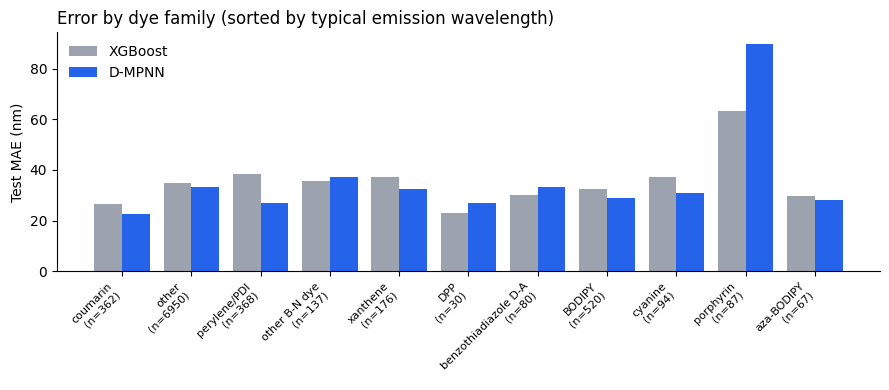

In [19]:
import matplotlib.pyplot as plt

tab = family_table(preds)
tab = tab[tab.molecules >= 5].sort_values("median true nm")
x = np.arange(len(tab))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, tab["XGB MAE"], 0.4, label="XGBoost", color="#9ca3af")
ax.bar(x + 0.2, tab["D-MPNN MAE"], 0.4, label="D-MPNN", color="#2563eb")
ax.set_xticks(x, [f"{f}\n(n={n})" for f, n in zip(tab.family, tab.n)], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Test MAE (nm)")
ax.set_title("Error by dye family (sorted by typical emission wavelength)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"{base}/results/fig_error_by_family.png", dpi=200)
plt.show()

preds.to_csv(f"{base}/results/predictions_with_families.csv", index=False)

In [15]:
preds[preds.family == "subphthalocyanine"][["seed", "solv", "true_nm", "xgb_nm", "dmpnn_nm"]]

,seed,solv,true_nm,xgb_nm,dmpnn_nm
6694,2,C1CCOC1,591.0,641.25290,906.943888
6695,2,C1COCCO1,590.0,633.40870,921.961366
6696,2,CC#N,586.0,636.52440,889.681733
6697,2,CC(=O)N(C)C,582.0,633.20830,895.941727
6698,2,CC(=O)OC(C)=O,588.0,637.08200,919.956635
6699,2,CC(C)=O,589.0,639.94240,899.716226
6700,2,CCC#N,581.0,640.71716,894.245695
6701,2,CCO,585.0,636.43365,897.148350
6702,2,CCOC(C)=O,588.0,636.40150,901.949576
6703,2,CCOCC,585.0,635.98535,904.211647
